<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Dataset Setup
First, we will generate the synthetic dataset for both the linearly separable Loan Application Screener and the non-linearly separable XOR pattern.

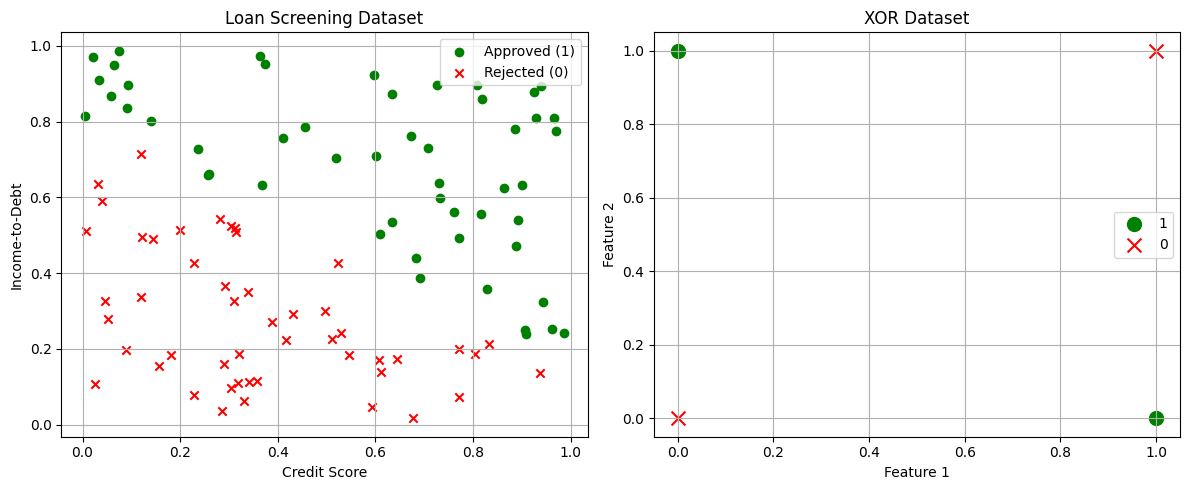

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# 1. Loan Application Screener Dataset (Linearly Separable)
# Features: Credit Score (normalized [0, 1]), Income-to-Debt Ratio (normalized [0, 1])
num_samples = 100
X_loan = np.random.rand(num_samples, 2)

# Linear decision boundary: Credit Score + 1.5 * Income-to-Debt - 1.2 > 0 -> Approved (1), else Rejected (0)
y_loan = (X_loan[:, 0] + 1.5 * X_loan[:, 1] - 1.2 > 0).astype(int)

# 2. XOR Dataset (Non-Linearly Separable)
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

# Plot both datasets
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot Loan Data
ax1.scatter(X_loan[y_loan == 1][:, 0], X_loan[y_loan == 1][:, 1], color='g', marker='o', label='Approved (1)')
ax1.scatter(X_loan[y_loan == 0][:, 0], X_loan[y_loan == 0][:, 1], color='r', marker='x', label='Rejected (0)')
ax1.set_title('Loan Screening Dataset')
ax1.set_xlabel('Credit Score')
ax1.set_ylabel('Income-to-Debt')
ax1.legend()
ax1.grid(True)

# Plot XOR Data
ax2.scatter(X_xor[y_xor == 1][:, 0], X_xor[y_xor == 1][:, 1], color='g', marker='o', s=100, label='1')
ax2.scatter(X_xor[y_xor == 0][:, 0], X_xor[y_xor == 0][:, 1], color='r', marker='x', s=100, label='0')
ax2.set_title('XOR Dataset')
ax2.set_xlabel('Feature 1')
ax2.set_ylabel('Feature 2')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Task 1: Implement Weighted Sum, Bias, and Step Activation
We will define the functions for computing the net input (weighted sum with bias) and the step activation function.

In [ ]:
def weighted_sum(X, weights, bias):
    """
    Calculate the weighted sum of inputs.
    X: feature matrix of shape (n_samples, n_features)
    weights: weight array of shape (n_features,)
    bias: bias scalar
    """
    return np.dot(X, weights) + bias

def step_activation(z):
    """
    Heaviside step function: 1 if z >= 0 else 0.
    """
    return np.where(z >= 0, 1, 0)

def perceptron_predict(X, weights, bias):
    """
    Forward propagation of the perceptron.
    """
    z = weighted_sum(X, weights, bias)
    return step_activation(z)

### Task 2: Train Perceptron on Loan Data
We train a single Perceptron using the Perceptron Learning Rule and track weight updates per epoch.

In [ ]:
def train_perceptron(X, y, learning_rate=0.1, epochs=50):
    n_samples, n_features = X.shape
    # Initialize weights and bias to zeros or small random values
    weights = np.zeros(n_features)
    bias = 0.0

    weight_history = []
    bias_history = []
    errors_per_epoch = []

    for epoch in range(epochs):
        total_error = 0
        for i in range(n_samples):
            prediction = perceptron_predict(X[i], weights, bias)
            error = y[i] - prediction
            if error != 0:
                # Perceptron learning rule updates
                weights += learning_rate * error * X[i]
                bias += learning_rate * error
                total_error += abs(error)

        weight_history.append(weights.copy())
        bias_history.append(bias)
        errors_per_epoch.append(total_error)

        if total_error == 0:
            print(f"Converged early at epoch {epoch+1}!")
            break

    return weights, bias, weight_history, bias_history, errors_per_epoch

weights_loan, bias_loan, w_hist, b_hist, err_hist = train_perceptron(X_loan, y_loan, learning_rate=0.1, epochs=100)
print("Final Weights:", weights_loan)
print("Final Bias:", bias_loan)

Converged early at epoch 5!
Final Weights: [0.33013339 0.50490205]
Final Bias: -0.4


### Task 3: Plot the Learned Decision Boundary
We will visualize the decision boundary of the perceptron alongside the classification of the loan database.

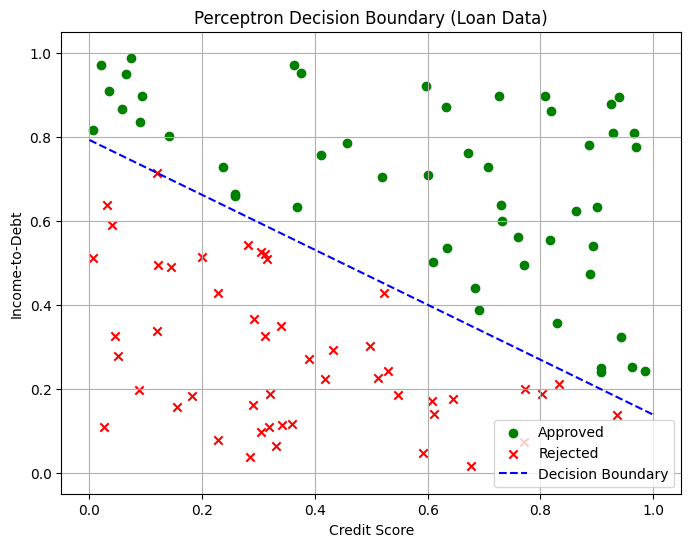

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_loan[y_loan == 1][:, 0], X_loan[y_loan == 1][:, 1], color='g', marker='o', label='Approved')
plt.scatter(X_loan[y_loan == 0][:, 0], X_loan[y_loan == 0][:, 1], color='r', marker='x', label='Rejected')

# Decision boundary line:
# w1 * x1 + w2 * x2 + b = 0  =>  x2 = -(w1 * x1 + b) / w2
x_values = np.linspace(0, 1, 100)
y_values = -(weights_loan[0] * x_values + bias_loan) / weights_loan[1]

plt.plot(x_values, y_values, color='blue', linestyle='--', label='Decision Boundary')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.xlabel('Credit Score')
plt.ylabel('Income-to-Debt')
plt.title('Perceptron Decision Boundary (Loan Data)')
plt.legend()
plt.grid(True)
plt.show()

### Task 4: Train on XOR Data
Let us attempt to train the perceptron on the XOR dataset and observe its failure to converge.

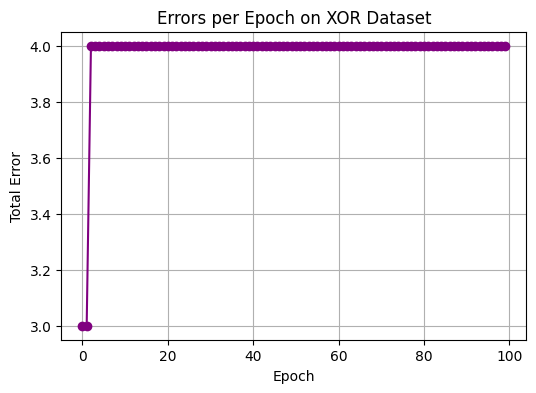

Since the XOR logic gate is not linearly separable, a single perceptron cannot find a decision boundary to separate the classes, leading to continuous oscillation and non-convergence.


In [ ]:
weights_xor, bias_xor, _, _, err_hist_xor = train_perceptron(X_xor, y_xor, learning_rate=0.1, epochs=100)

plt.figure(figsize=(6, 4))
plt.plot(err_hist_xor, marker='o', color='purple')
plt.title('Errors per Epoch on XOR Dataset')
plt.xlabel('Epoch')
plt.ylabel('Total Error')
plt.grid(True)
plt.show()

print("Since the XOR logic gate is not linearly separable, a single perceptron cannot find a decision boundary to separate the classes, leading to continuous oscillation and non-convergence.")

### Task 5: Compare Activation Functions
We will implement the Step, Sigmoid, and ReLU functions and visualize their outputs across a range of continuous inputs.

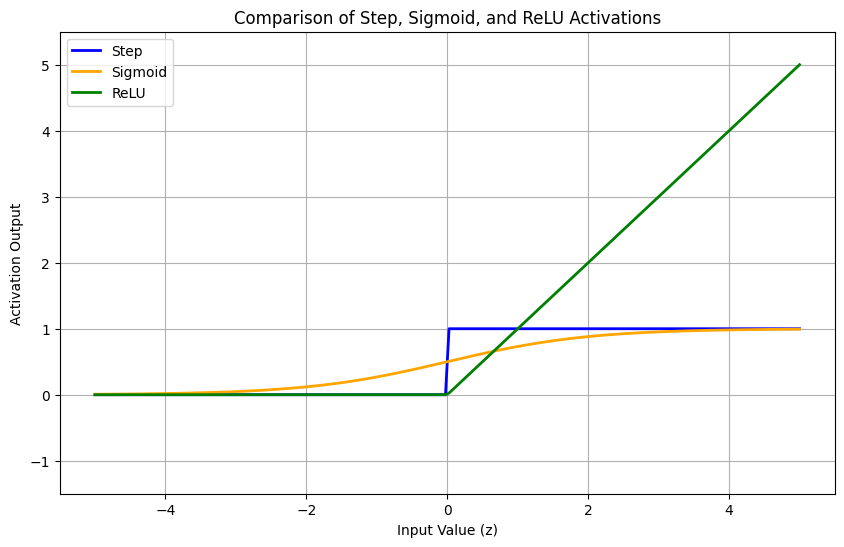

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

z_range = np.linspace(-5, 5, 200)

plt.figure(figsize=(10, 6))
plt.plot(z_range, step_activation(z_range), label='Step', color='blue', linewidth=2)
plt.plot(z_range, sigmoid(z_range), label='Sigmoid', color='orange', linewidth=2)
plt.plot(z_range, relu(z_range), label='ReLU', color='green', linewidth=2)

plt.title('Comparison of Step, Sigmoid, and ReLU Activations')
plt.xlabel('Input Value (z)')
plt.ylabel('Activation Output')
plt.grid(True)
plt.legend()
plt.ylim(-1.5, 5.5)
plt.show()